# Final Project Phase 3 Summary
This Jupyter Notebook (.ipynb) will serve as the skeleton file for your submission for Phase 3 of the Final Project. Complete all sections below as specified in the instructions for the project, covering all necessary details. We will use this to grade your individual code (Do this whether you are in a group or not). Good luck! <br><br>

Note: To edit a Markdown cell, double-click on its text.

# Video Presentation

If you uploaded your Video Presentation to Bluejeans, YouTube, or any other streaming services, please provide the link here:


*   Video Presentation Link

[LINK FOR YOUTUBE PRESENTATION](https://youtu.be/fM9PhJFS2rw)


## Data Sources
Include sources (as links) to your datasets. Add any additional data sources if needed. Clearly indicate if a data source is different from one submitted in your Phase I, as we will check that it satisfies the requirements.
*   Downloaded Dataset Source:https://collegescorecard.ed.gov/data (download the one titled: “Most Recent Institution- Level Data)
*   Web Collection #1 Source: https://en.wikipedia.org/wiki/List_of_U.S._states_and_territories_by_educational_attainment
*   Web Collection #2 Source: https://api.census.gov/data/2022/acs/acs5/variables.html

# Data Collection and Cleaning


Transfer/update the data collection and cleaning you created for Phase II below. You may include additional cleaning functions if you have extra datasets. If no changes are necessary, simply copy and paste your phase II parsing/cleaning functions.


## Downloaded Dataset Requirement



In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)
os.chdir('/content/drive/MyDrive/CS2316 Data Project')
print(os.getcwd())

Mounted at /content/drive
/content/drive/MyDrive/CS2316 Data Project


In [ ]:
import pandas as pd
import numpy as np

def downloaded_dataset_parser(file_path="Most-Recent-Cohorts-Institution.csv"):
    #load dataset
    scorecard1 = pd.read_csv(file_path, low_memory=False)

    #keep only columns needed for the project
    wanted_cols = [
        "UNITID",
        "INSTNM",
        "STABBR",
        "ZIP",
        "CONTROL",
        "TUITIONFEE_IN",
        "TUITIONFEE_OUT",
        "DEBT_MDN",
        "ADM_RATE",
        "SAT_AVG",
        "C150_4",
        "C150_L4"
    ]

    scorecard = scorecard1[wanted_cols].copy()

    #replace common "missing" strings with NaN
    missing_tokens = ["NULL", "NaN", "nan", "PrivacySuppressed", "Not Available","N/A", "n/a", "", " "]
    scorecard = scorecard.replace(missing_tokens, np.nan)

    #combine columns for graduation rate
    for row in scorecard.index:
        if pd.isna(scorecard.loc[row, "C150_4"]):
          scorecard.loc[row,"C150_4"] = scorecard.loc[row,"C150_L4"]
    scorecard.drop(columns="C150_L4", inplace=True)
    scorecard.rename(columns={"C150_4": "GRAD_RATE"}, inplace=True)

    grad_col = "GRAD_RATE"

    #clean text columns
    if "INSTNM" in scorecard.columns:
        scorecard["INSTNM"] = scorecard["INSTNM"].astype(str).str.strip()

    if "STABBR" in scorecard.columns:
        scorecard["STABBR"] = scorecard["STABBR"].astype(str).str.strip().str.upper()

    if "ZIP" in scorecard.columns:
        scorecard["ZIP"] = scorecard["ZIP"].astype(str).str.extract(r"(\d+)")[0].str.zfill(5)

    #convert numeric columns
    numeric_cols = ["TUITIONFEE_IN", "TUITIONFEE_OUT", "DEBT_MDN", "ADM_RATE", "SAT_AVG"]
    if grad_col is not None:
        numeric_cols.append(grad_col)

    for col in numeric_cols:
        scorecard[col] = pd.to_numeric(scorecard[col], errors="coerce")

    # Remove exact duplicate schools by UNITID
    scorecard = scorecard.drop_duplicates(subset=["UNITID"])

    #fill missing tuition/debt values using state + control medians first, then state medians
    fill_cols = ["TUITIONFEE_IN", "TUITIONFEE_OUT", "DEBT_MDN"]
    for col in fill_cols:
        if "STABBR" in scorecard.columns and "CONTROL" in scorecard.columns:
              scorecard[col] = scorecard[col].fillna(scorecard.groupby(["STABBR", "CONTROL"])[col].transform("median"))

    #fill missing graduation column using state medians
    if grad_col is not None and "STABBR" in scorecard.columns:
        scorecard[grad_col] = scorecard[grad_col].fillna(scorecard.groupby("STABBR")[grad_col].transform("median"))

    #fill missing admission rate / SAT with state medians
    for row in ["ADM_RATE", "SAT_AVG"]:
        scorecard[col] = scorecard[col].fillna(scorecard.groupby("STABBR")[col].transform("median"))

    for row in ["TUITIONFEE_IN", "TUITIONFEE_OUT", "DEBT_MDN", "SAT_AVG"]:
        scorecard[col] = scorecard[col].round(2)

    for row in ["ADM_RATE"]:
        scorecard[col] = scorecard[col].round(4)

    if grad_col is not None and grad_col in scorecard.columns:
        scorecard[grad_col] = scorecard[grad_col].round(4)

    #remove unreasonable negatives
    for col in numeric_cols:
        scorecard.loc[scorecard[col] < 0, col] = np.nan

    #export cleaned dataset
    scorecard.to_csv("cleaned_scorecard.csv", index=False)

    return scorecard


############ Function Call ############
downloaded_dataset_parser()

,UNITID,INSTNM,STABBR,ZIP,CONTROL,TUITIONFEE_IN,TUITIONFEE_OUT,DEBT_MDN,ADM_RATE,SAT_AVG,GRAD_RATE
0,100654,Alabama A & M University,AL,35762,1,10024.0,18634.0,16600.0,0.6622,947.0,0.2874
1,100663,University of Alabama at Birmingham,AL,35294,1,8832.0,21864.0,15832.0,0.8842,1251.0,0.6260
2,100690,Amridge University,AL,36117,2,19688.0,19688.0,13385.0,NaN,NaN,0.4000
3,100706,University of Alabama in Huntsville,AL,35899,1,11770.0,24662.0,13905.0,0.7425,1321.0,0.6191
4,100724,Alabama State University,AL,36104,1,11248.0,19576.0,17500.0,0.9564,977.0,0.3018
...,...,...,...,...,...,...,...,...,...,...,...
6424,49382201,College Unbound - Newport/Aquidneck Island,RI,028400000,2,10488.0,10488.0,7690.0,NaN,NaN,0.7021
6425,49425001,Valley College - Fairlawn - School of Nursing,OH,443333631,3,16699.0,16699.0,9418.0,NaN,NaN,0.5979
6426,49501301,Western Maricopa Education Center - Southwest ...,AZ,85326,1,2358.0,8958.0,8000.0,NaN,NaN,0.5484
6427,49501302,Western Maricopa Education Center - Northeast ...,AZ,85027,1,2358.0,8958.0,8000.0,NaN,NaN,0.5484


## Web Collection Requirement \#1


In [ ]:
import requests
import pandas as pd
import numpy as np

def api_dataset_parser(year=2023, save_path="cleaned_census_income.csv"):
    # this is the census acs 5-year api endpoint
    url = f"https://api.census.gov/data/{year}/acs/acs5"
    params = {
        # these are the columns i want back from the api
        "get": "NAME,B19013_001E,B19013_001M",
        # this gets all states , queries come from census query components reference
        "for": "state:*"
    }

    # calling the api and turning the response into json
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    data = response.json()

    # first row has the headers, the rest are the actual rows
    headers = data[0]
    rows = data[1:]
    census_df = pd.DataFrame(rows, columns=headers)

    # renaming columns so they are easier to read later
    census_df = census_df.rename(columns={
        "NAME": "stateName",
        "B19013_001E": "medianHouseholdIncome",
        "B19013_001M": "incomeMarginOfError",
        "state": "stateFips"
    })

    # replacing common missing values with nan
    census_df = census_df.replace(["NULL", "", " "], np.nan)

    # converting numeric columns from strings into actual numbers
    census_df["medianHouseholdIncome"] = pd.to_numeric(census_df["medianHouseholdIncome"], errors="coerce")
    census_df["incomeMarginOfError"] = pd.to_numeric(census_df["incomeMarginOfError"], errors="coerce")

    # making sure state fips codes stay 2 digits
    census_df["stateFips"] = census_df["stateFips"].astype(str).str.zfill(2)

    # this dictionary helps match full state names to abbreviations
    state_name_to_abbr = {
        "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
        "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
        "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI",
        "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
        "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
        "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
        "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
        "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
        "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
        "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
        "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
        "Vermont": "VT", "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
        "Wisconsin": "WI", "Wyoming": "WY", "Puerto Rico": "PR"
    }

    # making a new column with state abbreviations so it can match scorecard later
    census_df["STABBR"] = census_df["stateName"].map(state_name_to_abbr)

    # keeping only rows where the abbreviation was found
    census_df = census_df[census_df["STABBR"].notna()].copy()

    # rounding numeric columns so they look cleaner
    census_df["medianHouseholdIncome"] = census_df["medianHouseholdIncome"].round(2)
    census_df["incomeMarginOfError"] = census_df["incomeMarginOfError"].round(2)

    # saving the cleaned dataframe to a csv file
    census_df.to_csv(save_path, index=False)

    print("cleaned census income shape:", census_df.shape)
    print(census_df.head())

    return census_df


############ function call ############
api_dataset_parser()

cleaned census income shape: (52, 5)
    stateName  medianHouseholdIncome  incomeMarginOfError stateFips STABBR
0     Alabama                  62027                  400        01     AL
1      Alaska                  89336                 1374        02     AK
2     Arizona                  76872                  414        04     AZ
3    Arkansas                  58773                  503        05     AR
4  California                  96334                  298        06     CA


,stateName,medianHouseholdIncome,incomeMarginOfError,stateFips,STABBR
0,Alabama,62027,400,01,AL
1,Alaska,89336,1374,02,AK
2,Arizona,76872,414,04,AZ
3,Arkansas,58773,503,05,AR
4,California,96334,298,06,CA
5,Colorado,92470,483,08,CO
6,Connecticut,93760,669,09,CT
7,Delaware,82855,1234,10,DE
8,District of Columbia,106287,1803,11,DC
9,Florida,71711,282,12,FL


## Web Collection Requirement #2

In [ ]:
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import requests

def html_parser(save_path="cleaned_html_data.csv"):
    url = "https://en.wikipedia.org/wiki/List_of_U.S._states_and_territories_by_educational_attainment"

    # using a user agent so wikipedia lets the request through
    agent = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/97.0.4692.99 Safari/537.36"
    }
    res = requests.get(url, headers=agent)
    res.raise_for_status()

    # grabbing the correct table
    soup = BeautifulSoup(res.text, "html.parser")
    table = soup.find_all("table")[1]

    # cleaning up the header names
    header = table.find_all("th")
    header = [i.text.strip("\n") for i in header]
    header = [i.replace(",", "") for i in header]
    header = [i.replace("%", "") for i in header]
    header = header[:5] + header[-8:]
    total = header[-8:]

    new_h = []
    for r in range(5):
        if r in [2, 3, 4]:
            new_h.append(header[r] + "(Population)")
            new_h.append(header[r] + "(Percent)")
        else:
            new_h.append(header[r])

    # getting row data
    row = table.find_all("tr")

    for i in range(len(row)):
        row[i] = row[i].find_all("td")
        for j in range(len(row[i])):
            row[i][j] = row[i][j].text.strip("\n")
            row[i][j] = row[i][j].replace(",", "")
            row[i][j] = row[i][j].replace("%", "")

    # making dataframe
    df = pd.DataFrame(row, columns=new_h)

    # removing empty rows
    df = df.iloc[2:]
    df.reset_index(drop=True, inplace=True)

    # putting total row back in case it got shifted
    df.iloc[-1] = total

    # converting columns to numbers
    df.iloc[:, 3] = pd.to_numeric(df.iloc[:, 3], errors="coerce") / 100
    df.iloc[:, 5] = pd.to_numeric(df.iloc[:, 5], errors="coerce") / 100
    df.iloc[:, -1] = pd.to_numeric(df.iloc[:, -1], errors="coerce") / 100
    df.iloc[:, 1] = pd.to_numeric(df.iloc[:, 1], errors="coerce")
    df.iloc[:, 2] = pd.to_numeric(df.iloc[:, 2], errors="coerce")
    df.iloc[:, 4] = pd.to_numeric(df.iloc[:, 4], errors="coerce")
    df.iloc[:, 6] = pd.to_numeric(df.iloc[:, 6], errors="coerce")

    # removing total row for analysis
    df = df[df["State or Territory"] != "Total"].copy()


    df["State or Territory"] = df["State or Territory"].astype(str).str.strip()
    df["State or Territory"] = df["State or Territory"].str.replace(r"\[.*?\]", "", regex=True)

    # mapping state names to abbreviations here so the merge is easier later
    state_name_to_abbr = {
        "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
        "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
        "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI",
        "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
        "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
        "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
        "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
        "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
        "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
        "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
        "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
        "Vermont": "VT", "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
        "Wisconsin": "WI", "Wyoming": "WY", "Puerto Rico": "PR"
    }

    df["STABBR"] = df["State or Territory"].map(state_name_to_abbr)

    # keeping only rows that mapped correctly
    df = df[df["STABBR"].notna()].copy()

    # saving cleaned html dataset
    df.to_csv(save_path, index=False)


    return df


############ Function Call ############
html_parser()

,State or Territory,Population over the age of 25,With a High School Diploma or higher(Population),With a High School Diploma or higher(Percent),With a Bachelor's Degree or higher(Population),With a Bachelor's Degree or higher(Percent),With an Advanced Degree(Population),With an Advanced Degree(Percent),STABBR
0,Alabama,3451208,3034741,0.8793,946766,0.2743,374490,0.1085,AL
1,Alaska,485779,453289,0.9331,159290,0.3279,57868,0.1191,AK
2,Arizona,4980297,4430934,0.8897,1615081,0.3243,629408,0.1264,AZ
3,Arkansas,2037763,1806873,0.8867,515034,0.2527,190897,0.0937,AR
4,California,26909869,22724990,0.8445,9737817,0.3619,3779787,0.1405,CA
5,Colorado,4044182,3738208,0.9243,1796240,0.4442,688931,0.1704,CO
6,Connecticut,2534376,2309185,0.9111,1067671,0.4213,479981,0.1894,CT
7,Delaware,711104,649638,0.9136,253292,0.3562,106997,0.1505,DE
8,District of Columbia,478774,444233,0.9279,301852,0.6305,181081,0.3782,DC
9,Florida,15762122,14153579,0.8979,5226846,0.3316,1978625,0.1255,FL


## Inconsistency Revisions
 **If you were requested to revise your inconsistency section from Phase II, enter your responses here. Otherwise, ignore this section.**

For each inconsistency (NaN, null, duplicate values, empty strings, etc.) you discover in your datasets, write at least 2 sentences stating the significance, how you identified it, and how you handled it.

1. N/A

2. N/A

3. N/A

4. (if applicable)

5. (if applicable)


# Data Analysis
For the Data Analysis section, you are required to utilize your data to complete the following:

*   Create at least 5 insights
*   Generate at least 3 data visualizations

Create a function for each of the following sections mentioned above. Do not forget to fill out the explanation section for each function.

Make sure your data analysis is not too simple. Performing complex aggregation and using modules not taught in class shows effort, which will increase the chance of receiving full credit.

# Topic Summary

Please provide a brief executive summary (5 sentences or less) discussing your topic:

This project analyzes how college costs, student debt, and educational outcomes vary across U.S. states. By combining data on tuition, household income, and educational attainment, it explores how affordability differs depending on economic context. The analysis shows that tuition alone does not determine affordability, as states with lower incomes often face a higher financial burden. It also finds that higher levels of educational attainment are strongly associated with higher tuition levels. Overall, the results suggest that college costs are closely tied to broader state-level economic and educational conditions rather than being randomly distributed.

# SETUP FOR INSIGHTS:
This code cell aggregates all the cleaned data from earlier, so it can be distinct from the insight-specific code onwards. All insights have references to setup cell comments.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score

# read cleaned files
scorecard = pd.read_csv("cleaned_scorecard.csv")
income = pd.read_csv("cleaned_census_income.csv")
attain = pd.read_csv("cleaned_html_data.csv")

state_col = attain.columns[0]

state_name_to_abbr = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
    "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
    "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY", "Puerto Rico": "PR"
}

attain["STABBR"] = attain[state_col].map(state_name_to_abbr)

# keep only rows that mapped correctly
attain = attain[attain["STABBR"].notna()].copy()

state_col = "State or Territory"
bachelors_col = "With a Bachelor's Degree or higher(Percent)"
grad_deg_col = "With an Advanced Degree(Percent)"


# aggregate scorecard to state level
# setup reference for insight 3: creates state-level averages for debt and graduation rate using groupby aggregation
# setup reference for insight 4: creates the state-level average in-state tuition used as the target variable in the regression model
# setup reference for insight 5: creates state-level averages (tuition, debt, graduation rate) used as clustering features
state_data = scorecard.groupby("STABBR").agg(
    avg_in_tuition=("TUITIONFEE_IN", "mean"),
    avg_out_tuition=("TUITIONFEE_OUT", "mean"),
    avg_debt=("DEBT_MDN", "mean"),
    avg_adm_rate=("ADM_RATE", "mean"),
    avg_sat=("SAT_AVG", "mean"),
    avg_grad_rate=("GRAD_RATE", "mean"),
    school_count=("UNITID", "count")
).reset_index()

# add public/private averages too for stronger analysis
# setup reference for insight 2: creates state-level public and private tuition averages used to compare tuition differences
public_private = scorecard.groupby(["STABBR", "CONTROL"]).agg(
    tuition=("TUITIONFEE_IN", "mean"),
    debt=("DEBT_MDN", "mean")
).reset_index()

public_tuition = public_private[public_private["CONTROL"] == 1][["STABBR", "tuition"]].rename(columns={"tuition": "public_avg_tuition"})
private_tuition = public_private[public_private["CONTROL"] == 2][["STABBR", "tuition"]].rename(columns={"tuition": "private_avg_tuition"})

state_data = state_data.merge(public_tuition, on="STABBR", how="left")
state_data = state_data.merge(private_tuition, on="STABBR", how="left")

# merge income
# setup reference for insight 4: merges median household income into the state-level dataset for use as a regression feature
# setup reference for insight 5: adds median household income to the state-level dataset for clustering
state_data = state_data.merge(
    income[["STABBR", "medianHouseholdIncome"]],
    on="STABBR",
    how="left"
)

# merge attainment
# setup reference for insight 4: merges bachelor’s degree percentage into the state-level dataset for use as a regression feature
# setup reference for insight 5: adds bachelor's degree percentage to the state-level dataset for clustering
state_data = state_data.merge(
    attain[["STABBR", bachelors_col, grad_deg_col]],
    on="STABBR",
    how="left"
)

state_data = state_data.rename(columns={
    bachelors_col: "bachelors_percent",
    grad_deg_col: "graduate_percent"
})

# create some helpful derived columns

# setup reference for insight 1: this creates the tuition-to-income ratio used to measure state-level college affordability:
state_data["tuition_income_ratio"] = state_data["avg_in_tuition"] / state_data["medianHouseholdIncome"]

# setup reference for insight 3: creates the debt-to-income ratio used to measure financial burden relative to income
state_data["debt_income_ratio"] = state_data["avg_debt"] / state_data["medianHouseholdIncome"]

# setup reference for insight 2: calculates the difference between private and public tuition for each state
state_data["private_public_gap"] = state_data["private_avg_tuition"] - state_data["public_avg_tuition"]

print(state_data.head())
print(state_data.shape)

  STABBR  avg_in_tuition  avg_out_tuition      avg_debt  avg_adm_rate  \
0     AK    11374.900000     17025.550000   9685.600000      0.761475   
1     AL    11830.273810     15168.916667  13039.089286      0.726800   
2     AR    11616.600000     12982.482353   9252.858824      0.719460   
3     AS     5460.000000      5760.000000           NaN           NaN   
4     AZ    12391.971311     15219.741803   9249.237705      0.830171   

       avg_sat  avg_grad_rate  school_count  public_avg_tuition  \
0          NaN       0.494260            10         7137.800000   
1  1131.789474       0.429887            84         7500.285714   
2  1094.705882       0.470086            85         5257.444444   
3          NaN       0.477400             1         5460.000000   
4  1147.500000       0.529519           122         3839.093023   

   private_avg_tuition  medianHouseholdIncome  bachelors_percent  \
0         13568.000000                89336.0             0.3279   
1         18550.666667

## Insights

In [ ]:
def insight1():
  # insight 1 reference: uses the merged state_data dataframe from the setup cell, especially the tuition_income_ratio column created there
    result = state_data[["STABBR", "avg_in_tuition", "medianHouseholdIncome", "tuition_income_ratio"]].copy()
    result = result.sort_values("tuition_income_ratio", ascending=False).head(10)
    print("top 10 states with the highest in-state tuition burden relative to household income")
    print(result)
    return result

############ Function Call ############
insight1()

top 10 states with the highest in-state tuition burden relative to household income
   STABBR  avg_in_tuition  medianHouseholdIncome  tuition_income_ratio
54     VT    41645.857143                78024.0              0.533757
46     RI    34939.312500                86372.0              0.404521
15     IA    23501.786667                73147.0              0.321295
44     PR     7850.643357                25096.0              0.312824
24     ME    22339.451613                71773.0              0.311251
43     PA    23185.190332                76081.0              0.304744
26     MI    21122.832370                71149.0              0.296882
22     MA    29668.646259               101341.0              0.292761
7      CT    24987.174603                93760.0              0.266501
20     KY    16606.057471                62417.0              0.266050


,STABBR,avg_in_tuition,medianHouseholdIncome,tuition_income_ratio
54,VT,41645.857143,78024.0,0.533757
46,RI,34939.312500,86372.0,0.404521
15,IA,23501.786667,73147.0,0.321295
44,PR,7850.643357,25096.0,0.312824
24,ME,22339.451613,71773.0,0.311251
43,PA,23185.190332,76081.0,0.304744
26,MI,21122.832370,71149.0,0.296882
22,MA,29668.646259,101341.0,0.292761
7,CT,24987.174603,93760.0,0.266501
20,KY,16606.057471,62417.0,0.266050


### Insight 1 Explanation

This insight shows which states have the highest in-state tuition burden when tuition is compared to median household income rather than just listed by raw tuition alone. That makes the analysis more meaningful because a state with moderate tuition can still be less affordable if income is lower. The main conclusion is that affordability changes when economic context is added, and that raw tuition by itself does not tell the full story. This matters because students and families are more affected by the relationship between tuition and income than by tuition alone.

In [ ]:
def insight2():
  # insight 2 reference: uses public and private tuition averages and the private_public_gap column created in the setup cell
    result = state_data[["STABBR", "public_avg_tuition", "private_avg_tuition", "private_public_gap"]].copy()
    result = result.dropna()
    result = result.sort_values("private_public_gap", ascending=False).head(10)
    print("top 10 states with the largest private vs public in-state tuition gap")
    print(result)
    return result

############ Function Call ############
insight2()

top 10 states with the largest private vs public in-state tuition gap
   STABBR  public_avg_tuition  private_avg_tuition  private_public_gap
54     VT        11283.333333         49926.545455        38643.212121
22     MA         8164.190476         45982.282051        37818.091575
7      CT        13850.937500         47239.105263        33388.167763
5      CA         2925.192090         34828.532967        31903.340877
23     MD         6669.433333         38279.736842        31610.303509
6      CO         7251.575758         38449.000000        31197.424242
42     OR         7752.461538         38581.304348        30828.842809
8      DC         6152.000000         36536.533333        30384.533333
46     RI        10906.666667         40485.307692        29578.641026
24     ME         7457.800000         36291.000000        28833.200000


,STABBR,public_avg_tuition,private_avg_tuition,private_public_gap
54,VT,11283.333333,49926.545455,38643.212121
22,MA,8164.190476,45982.282051,37818.091575
7,CT,13850.937500,47239.105263,33388.167763
5,CA,2925.192090,34828.532967,31903.340877
23,MD,6669.433333,38279.736842,31610.303509
6,CO,7251.575758,38449.000000,31197.424242
42,OR,7752.461538,38581.304348,30828.842809
8,DC,6152.000000,36536.533333,30384.533333
46,RI,10906.666667,40485.307692,29578.641026
24,ME,7457.800000,36291.000000,28833.200000


### Insight 2 Explanation

This insight compares average private and public tuition within each state to measure how large the sector gap is. Instead of only looking at one type of institution, this shows how much more expensive private institutions tend to be within the same state environment. The conclusion is that some states have a much wider private-public tuition gap than others, which could affect students’ college options depending on what sector they consider. This is meaningful because it highlights how the structure of higher education costs varies across states, not just across schools.

In [ ]:
def insight3():
  # insight 3 reference: uses state-level averages (avg_debt, avg_grad_rate) and the debt_income_ratio column created in the setup cell
    df = state_data[["STABBR", "avg_debt", "avg_grad_rate", "debt_income_ratio"]].dropna().copy()

    corr1 = df["avg_debt"].corr(df["avg_grad_rate"])
    corr2 = df["debt_income_ratio"].corr(df["avg_grad_rate"])

    result = df.sort_values("debt_income_ratio", ascending=False).head(10)

    print("correlation between average debt and graduation rate:", round(corr1, 4))
    print("correlation between debt-to-income ratio and graduation rate:", round(corr2, 4))
    print("\ntop 10 states with highest debt relative to income")
    print(result)

    return corr1, corr2, result

############ Function Call ############
insight3()

correlation between average debt and graduation rate: 0.3576
correlation between debt-to-income ratio and graduation rate: -0.0116

top 10 states with highest debt relative to income
   STABBR      avg_debt  avg_grad_rate  debt_income_ratio
44     PR   8058.713287       0.543466           0.321115
1      AL  13039.089286       0.429887           0.210216
48     SD  14162.730769       0.528477           0.195561
43     PA  14302.058912       0.608214           0.187985
57     WV  10780.139706       0.598043           0.186131
54     VT  14094.468750       0.630081           0.180643
30     MS   9889.410714       0.522714           0.180086
28     MO  11941.686275       0.577516           0.173269
34     NE  12984.650000       0.561055           0.173163
18     IN  11933.993007       0.576273           0.170361


(np.float64(0.35759924949518657),
 np.float64(-0.011568985159584884),
    STABBR      avg_debt  avg_grad_rate  debt_income_ratio
 44     PR   8058.713287       0.543466           0.321115
 1      AL  13039.089286       0.429887           0.210216
 48     SD  14162.730769       0.528477           0.195561
 43     PA  14302.058912       0.608214           0.187985
 57     WV  10780.139706       0.598043           0.186131
 54     VT  14094.468750       0.630081           0.180643
 30     MS   9889.410714       0.522714           0.180086
 28     MO  11941.686275       0.577516           0.173269
 34     NE  12984.650000       0.561055           0.173163
 18     IN  11933.993007       0.576273           0.170361)

### Insight 3 Explanation

This insight looks at whether higher debt levels are associated with lower graduation rates, especially when debt is considered relative to household income. The debt-to-income ratio is more useful than debt alone because it reflects how heavy that debt may feel in each state’s economic setting. The conclusion comes from the correlation values and the ranking of states with the highest debt burden relative to income. This matters because it helps connect student debt to student outcomes in a more realistic and policy-relevant way.

In [ ]:
def insight4():
  # insight 4 reference: uses avg_in_tuition from the state-level aggregation and the medianHouseholdIncome and bachelors_percent columns created through the setup merges
    df = state_data[["medianHouseholdIncome", "bachelors_percent", "avg_in_tuition"]].dropna().copy()

    X = df[["medianHouseholdIncome", "bachelors_percent"]]
    y = df["avg_in_tuition"]

    model = LinearRegression()
    model.fit(X, y)
    preds = model.predict(X)

    r2 = r2_score(y, preds)

    coef_df = pd.DataFrame({
        "feature": X.columns,
        "coefficient": model.coef_
    })

    print("linear regression model predicting average in-state tuition")
    print("intercept:", model.intercept_)
    print("r^2:", round(r2, 4))
    print(coef_df)

    return coef_df, r2
  ##VISUALIZATION 3 IS A REGRESSION VISUAL
############ Function Call ############
insight4()

linear regression model predicting average in-state tuition
intercept: -1247.0511207351337
r^2: 0.3291
                 feature   coefficient
0  medianHouseholdIncome     -0.004337
1      bachelors_percent  53387.196986


(                 feature   coefficient
 0  medianHouseholdIncome     -0.004337
 1      bachelors_percent  53387.196986,
 0.3291407746229982)

### Insight 4 Explanation

This regression model predicts average in-state tuition using median household income and the percentage of residents with bachelor’s degrees. The results show that the percentage of residents with bachelor’s degrees has a strong positive relationship with tuition, meaning states with higher educational attainment tend to have significantly higher tuition costs. On the other hand, median household income has a very small negative effect, suggesting that income alone does not strongly drive tuition levels. The R² value of about 0.33 indicates that while these factors do explain some variation in tuition, there are still many other factors influencing college costs. This insight is meaningful because it shows that education levels in a state are more closely tied to tuition than income alone. This suggests that states with more educated populations may also have more competitive or expensive higher education systems.

In [ ]:
def insight5():
  # insight 5 reference: uses state-level features (avg_in_tuition, avg_debt, medianHouseholdIncome, bachelors_percent) created in the setup cell to perform k-means clustering
    df = state_data[["STABBR", "avg_in_tuition", "avg_debt", "medianHouseholdIncome", "bachelors_percent"]].dropna().copy()

    features = df[["avg_in_tuition", "avg_debt", "medianHouseholdIncome", "bachelors_percent"]]

    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    df["cluster"] = kmeans.fit_predict(features)

    cluster_summary = df.groupby("cluster")[["avg_in_tuition", "avg_debt", "medianHouseholdIncome", "bachelors_percent"]].mean()

    print("state clusters based on tuition, debt, income, and educational attainment")
    print(df[["STABBR", "cluster"]].sort_values("cluster"))
    print("\ncluster averages")
    print(cluster_summary)

    return cluster_summary

############ Function Call ############
insight5()

state clusters based on tuition, debt, income, and educational attainment
   STABBR  cluster
0      AK        0
7      CT        0
6      CO        0
5      CA        0
8      DC        0
14     HI        0
23     MD        0
22     MA        0
35     NH        0
27     MN        0
36     NJ        0
55     WA        0
46     RI        0
51     UT        0
52     VA        0
39     NY        0
37     NM        1
41     OK        1
44     PR        1
30     MS        1
20     KY        1
21     LA        1
2      AR        1
57     WV        1
1      AL        1
18     IN        2
16     ID        2
17     IL        2
12     GA        2
10     FL        2
9      DE        2
15     IA        2
33     ND        2
34     NE        2
31     MT        2
32     NC        2
28     MO        2
19     KS        2
24     ME        2
26     MI        2
4      AZ        2
42     OR        2
43     PA        2
47     SC        2
49     TN        2
48     SD        2
38     NV        2
40     OH     

,avg_in_tuition,avg_debt,medianHouseholdIncome,bachelors_percent
cluster,,,,
0,20198.018307,12114.691688,94522.312500,0.420637
1,11396.336856,10080.660161,56321.777778,0.268311
2,17023.949536,11245.275867,73843.111111,0.332585


### Insight 5 Explanation

This clustering analysis groups states into three distinct categories based on tuition, student debt, household income, and educational attainment. The results show a clear pattern: one cluster represents high-income, highly educated states with significantly higher tuition levels, while another cluster represents lower-income, less educated states with lower tuition. A third cluster falls in between, showing moderate values across all variables. This suggests that college costs are not randomly distributed but instead closely tied to broader socioeconomic conditions within each state. This insight is meaningful because it shows that education systems reflect the economic and educational structure of a state rather than operating independently.

## Data Visualizations

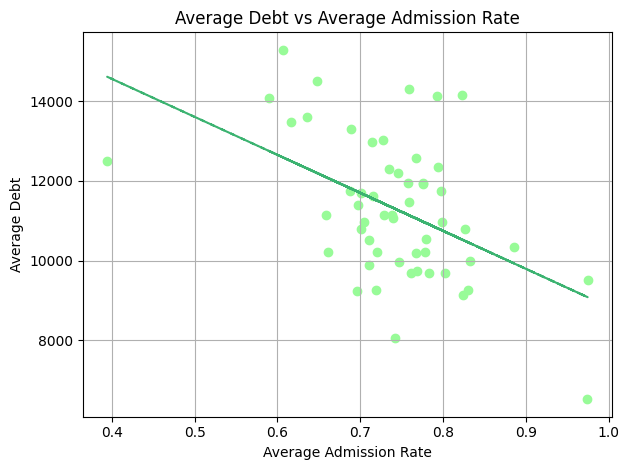

In [ ]:
def visual1():
  df = state_data[["avg_debt","avg_adm_rate"]].copy()
  df = df.dropna()
  x=df["avg_adm_rate"]
  y=df["avg_debt"]
  z=np.polyfit(x,y,1)
  p=np.poly1d(z)
  plt.scatter(x,y,color='palegreen')
  plt.plot(x,p(x),linestyle="--",color='mediumseagreen')
  plt.ylabel("Average Debt")
  plt.xlabel("Average Admission Rate")
  plt.title("Average Debt vs Average Admission Rate")
  plt.grid(True)
  plt.tight_layout()
  plt.show()

############ Function Call ############
visual1()

### Visualization 1 Explanation

This scatter plot visualizes the relationship between the average admissions rate and the average student debt in each state. Each point represents a state, the negative slope of the trendline implies that a state with a lower average admissions rate is likely to have a greater amount of average debt.

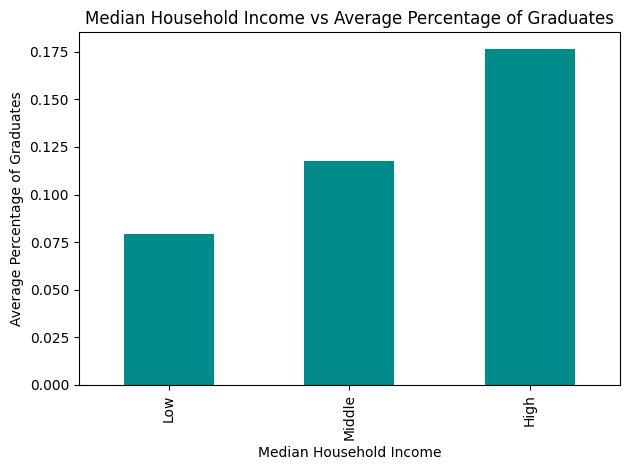

In [ ]:
def visual2():
  df = state_data[["medianHouseholdIncome","graduate_percent"]].copy()
  df = df.dropna()
  num=(df["medianHouseholdIncome"].max()-df["medianHouseholdIncome"].min())/3
  df["income_type"] =np.where(df["medianHouseholdIncome"]<=df["medianHouseholdIncome"].min()+num,'Low',np.where(df["medianHouseholdIncome"]<=df["medianHouseholdIncome"].max()-num,'Middle','High'))
  df = df.groupby("income_type")["graduate_percent"].mean()
  df=df.sort_values()
  ax=df.plot(kind="bar",color='darkcyan')
  plt.ylabel("Average Percentage of Graduates")
  plt.xlabel("Median Household Income")
  plt.title("Median Household Income vs Average Percentage of Graduates")
  plt.tight_layout()
  plt.show()

############ Function Call ############
visual2()

### Visualization 2 Explanation

This bar chart shows the average percentage of graduates across different categories of median household income: 'Low', 'Middle', and 'High'. The states are grouped into these income categories, and the average graduate percentage is calculated for each. This visualization helps to illustrate if states with higher median household incomes generally have a higher proportion of residents who are graduates due to the affordablity of the education.

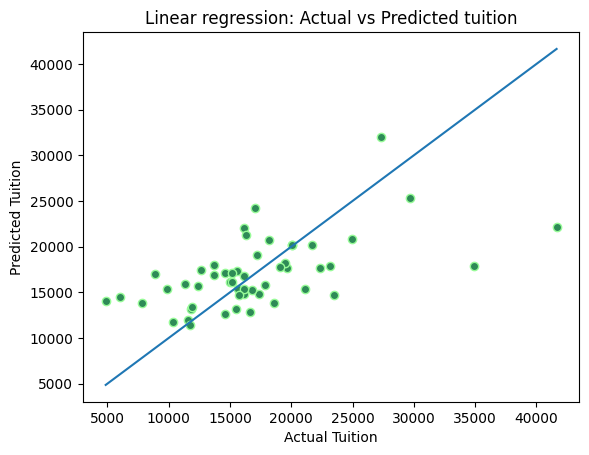

In [ ]:
def visual3():
    # using same data as regression INSIGHT 4
    df = state_data[["medianHouseholdIncome", "bachelors_percent", "avg_in_tuition"]].dropna().copy()

    X = df[["medianHouseholdIncome", "bachelors_percent"]]
    y = df["avg_in_tuition"]

    model = LinearRegression()
    model.fit(X, y)
    preds = model.predict(X)

    # plot actual vs predicted
    fig, ax = plt.subplots()

    ax.scatter(y, preds, color="seagreen", edgecolors="palegreen")

    # perfect prediction line
    min_val = min(y.min(), preds.min())
    max_val = max(y.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val])

    ax.set_xlabel("Actual Tuition")
    ax.set_ylabel("Predicted Tuition")
    ax.set_title("Linear regression: Actual vs Predicted tuition")

    plt.show()
visual3()

### Visualization 3 Explanation

This visualization builds on Insight 4 by showing how well the linear regression model predicts average in-state tuition using median household income and bachelor’s degree attainment. It compares actual tuition values to predicted values, where points closer to the diagonal line indicate more accurate predictions and points farther away indicate larger errors. The overall spread of the data reflects the moderate R² value from Insight 4, meaning the model captures general trends but does not fully explain all variation in tuition. This suggests that while income and education levels are important predictors, other factors also influence tuition differences across states.

# Cited Sources

If you used any additional sources to complete your Data Analysis section, list them here:


*   Example Module Documentation
*   Example Stack Overflow Assistance



# Submission

Prior to submitting your notebook to Gradescope, be sure to <b>run all functions within this file</b>. We will not run your functions ourselves, so we must see your outputs within this file in order to receive full credit.
